In [230]:
import ROOT
import numpy as np
import pandas as pd
from scipy.stats import f as f_dist
import math
import matplotlib.pyplot as plt
 
ROOT.gStyle.SetOptFit(1111)    # aggiunge il label con chi2/ndf e probabilita e parametri se metti 0000 toglie i dati
ROOT.gStyle.SetFitFormat(
    "4.2e"
)  # con 2 cifre decimali


ROOT.gROOT.SetBatch(True)

In [231]:
file_path = "esperienza5.xlsx"

sheets = {
    'Dati': 'Dati',
    'Manuele': 'Manuele',
    'Alessio': 'Alessio',
    'Emanuele': 'Emanuele',
    'Michele': 'Michele'
}

def load_data(sheet_name):
    try:
        df = pd.read_excel(file_path, sheet_name=sheet_name, skiprows=0)
        theta = pd.to_numeric(df.iloc[:, 0], errors='coerce')
        #print(theta)
        theta = theta.dropna()
        
        theta_val = theta.values.astype(np.float64)
        
        return theta_val
    except Exception as e:
        print(f"Errore nel caricamento del foglio {sheet_name}: {e}")
        return None, None


def IQR(dist):
    return np.percentile(dist, 75) - np.percentile(dist, 25)

In [232]:
root_objects = []
def make_hist(nomi, title, filename, bin):
    c = ROOT.TCanvas(f"c_{filename}", title, 800, 600)
    c.SetGrid()
    

    for name in nomi:
        if name in data:
            theta = data[name]

            gaussian_fit = ROOT.TF1('gaussian', 'gaus', min(theta), max(theta), 3)
            gaussian_fit.SetParNames("const", "mu", "sigma")
            gaussian_fit.SetLineColor(ROOT.kRed + 1)
            gaussian_fit.SetLineWidth(3)


            delta_bin = 2*IQR(theta)/ (len(theta))**(1/3)
            n_bin= (np.max(theta) - np.min(theta))/delta_bin
            n_bin = int(np.round(n_bin))

            hist = ROOT.TH1F("hist", f"{title}; θ_B; conteggi", bin , min(theta), max(theta))
                
            for val in theta:
                hist.Fill(val)
                leg = ROOT.TLegend(0.15, 0.70, 0.40, 0.85)
                leg.SetBorderSize(1)
                leg.SetFillStyle(1001)

        gaussian_fit.SetParameters(hist.GetMaximum(), hist.GetMean(), hist.GetRMS())
            
        hist.SetLineColor(ROOT.kAzure + 3)
        hist.SetLineWidth(2)
        hist.SetFillColorAlpha(ROOT.kAzure + 1, 0.55)   
        hist.GetXaxis().SetTitle("θ_B")
        hist.GetYaxis().SetTitle("conteggi")
        hist.SetTitle(f"{title}")

        r = hist.Fit(gaussian_fit, "S")

        fitStatus = r.Status()
        print(f"Fit status: {fitStatus}")

        parameters = gaussian_fit.GetParameters()
        errors = gaussian_fit.GetParErrors()

        chi2 = gaussian_fit.GetChisquare()
        '''
        print("Parametri stimati:")
        print(f"const = {parameters[0]} ± {errors[0]}")
        print(f"#mu = {parameters[1]} ± {errors[1]}")
        print(f"#sigma = {parameters[2]} ± {errors[2]}")
        print(f"Chi2 = {chi2}")
        print("\n")
        print("--------------------------------------------------------------")
        print("\n")
        '''
        root_objects.append(hist)

    hist.Draw()

    '''
    leg2 = ROOT.TLegend(0, 0.30, 0.15, 0.39)
    leg2.AddEntry(hist, "Residui", "f")
    leg2.AddEntry(gaussian_fit, "Fit gaussiano", "l")
    leg2.Draw()
    '''

    c.SaveAs(filename)


In [233]:
data = {}
for key, s_name in sheets.items():
    theta = load_data(s_name)
    data[key] = (theta) 


In [234]:
make_hist(['Dati'], 'Istogramma con tutti i dati', 'hist_totalData.png', 9)
make_hist(['Manuele'], 'Istogramma con i dati di Manuele', 'histManuData.png', 8)
make_hist(['Alessio'], 'Istogramma con i dati di Alessio', 'histAleData.png', 9)
make_hist(['Emanuele'], 'Istogramma con i dati di Emanuele', 'histStroiliData.png',7)
make_hist(['Michele'], 'Istogramma con i dati di Michele', 'histMichData.png', 8)

Fit status: 0
Fit status: 1
Fit status: 0
Fit status: 0
Fit status: 1
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      11.8569
NDf                       =            5
Edm                       =  8.43337e-07
NCalls                    =           74
const                     =      23.2242   +/-   3.70802     
mu                        =      56.7555   +/-   0.0564431   
sigma                     =     0.441517   +/-   0.0779489    	 (limited)
****************************************
Minimizer is Minuit2 / Migrad
Chi2                      =      2.55282
NDf                       =            4
Edm                       =  2.06581e-06
NCalls                    =          974
const                     =      649.297   +/-   1407.04     
mu                        =      50.2337   +/-   1.88957     
sigma                     =      2.06462   +/-   0.435309     	 (limited)
****************************************
Minimizer is Minuit2 / 

Info in <TCanvas::Print>: png file hist_totalData.png has been created
Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Info in <TCanvas::Print>: png file histManuData.png has been created
Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Info in <TCanvas::Print>: png file histAleData.png has been created
Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Info in <TCanvas::Print>: png file histStroiliData.png has been created
Warning in <TROOT::Append>: Replacing existing TH1: hist (Potential memory leak).
Info in <TCanvas::Print>: png file histMichData.png has been created


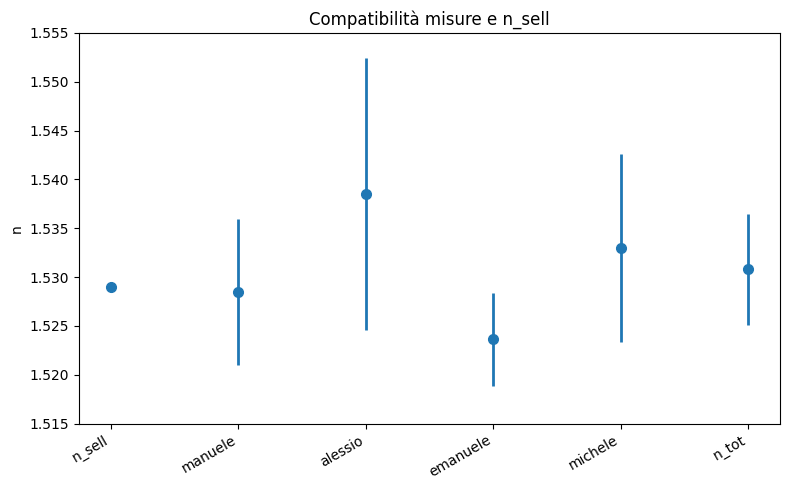

In [235]:
df = pd.read_excel(file_path, sheet_name='n', skiprows=0)
names = df.iloc[:,1]
n  = pd.to_numeric(df.iloc[:,0])
duesigma = pd.to_numeric(df.iloc[:,2])

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(names, n, yerr=duesigma, fmt="o", capsize=0, lw=2, ms=7)
ax.set_ylabel("n")
ax.set_ylim(1.515, 1.555)
plt.xticks(rotation=30, ha="right")   # per etichette lunghe
plt.title(f"Compatibilità misure e n_sell")
fig.tight_layout()
fig.savefig("pointrange.png", dpi=200)